In [7]:
import numpy as np
import matplotlib.pyplot as plt
from parflow.tools import Run
from parflow.tools.fs import mkdir, cp, get_absolute_path, exists
import matplotlib.pyplot as plt
from matplotlib import colors 
import matplotlib.dates as mdates
import matplotlib.colors as mcolors
from matplotlib.colors import TwoSlopeNorm
import matplotlib.patches as mpatches
from matplotlib.patches import Patch

from matplotlib.ticker import MultipleLocator


In [8]:
outflow_wet_b = np.load('~/pf_out_WY2017_baseline/overland_flow.npy')
outflow_wet_w = np.load('~/pf_out_WY2017_warm/overland_flow.npy')

outflow_dry_b = np.load('~/pf_out_WY2018_baseline/overland_flow.npy')
outflow_dry_w = np.load('~/pf_out_WY2018_warm/overland_flow.npy')

outflow_wet_b_rz0 = np.load('~/pf_out_WY2017_baseline_rz0/overland_flow.npy')
outflow_wet_w_rz0 = np.load('~/pf_out_WY2017_warm_rz0/overland_flow.npy')

outflow_dry_b_rz0 = np.load('~/pf_out_WY2018_baseline_rz0/overland_flow.npy')
outflow_dry_w_rz0 = np.load('~/pf_out_WY2018_warm_rz0/overland_flow.npy')

In [9]:
outflow_wet_b.shape

(8761,)

In [10]:
july_start_hr = 273*24


In [10]:
outflow_wet_b_summer = np.sum(outflow_wet_b[july_start_hr:-1])
outflow_wet_w_summer = np.sum(outflow_wet_w[july_start_hr:-1])

outflow_dry_b_summer = np.sum(outflow_dry_b[july_start_hr:-1])
outflow_dry_w_summer = np.sum(outflow_dry_w[july_start_hr:-1])

outflow_wet_b_summer_rz0 = np.sum(outflow_wet_b_rz0[july_start_hr:-1])
outflow_wet_w_summer_rz0 = np.sum(outflow_wet_w_rz0[july_start_hr:-1])

outflow_dry_b_summer_rz0 = np.sum(outflow_dry_b_rz0[july_start_hr:-1])
outflow_dry_w_summer_rz0 = np.sum(outflow_dry_w_rz0[july_start_hr:-1])

/tmp/ipykernel_2356432/2387913952.py:20: RuntimeWarning: invalid value encountered in scalar divide
  (outflow_dry_w_summer_rz0 - outflow_dry_b_summer_rz0)
/tmp/ipykernel_2356432/2387913952.py:25: RuntimeWarning: invalid value encountered in scalar divide
  (outflow_dry_w_summer - outflow_dry_b_summer)


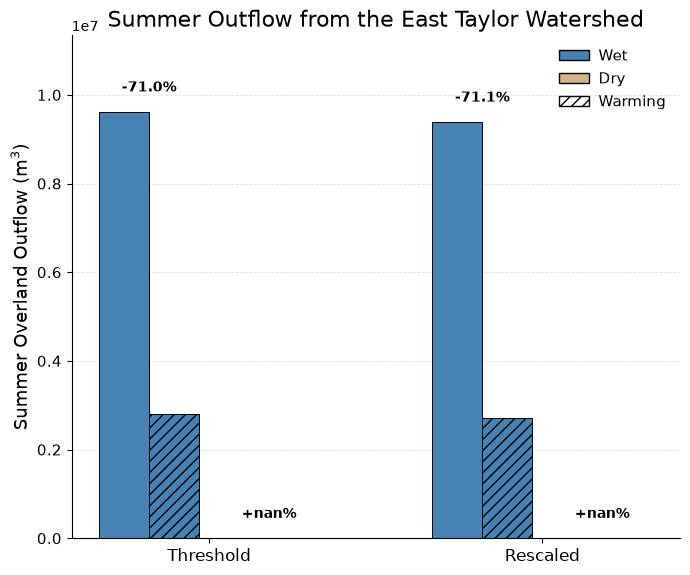

outflow wet baseline threshold :  9617813.91208002
outflow wet baseline rescaled :  9388513.293484196
outflow wet warm threshold :  2792435.6296298765
outflow wet warm rescaled :  2717665.060182268
outflow dry baseline threshold :  0.0
outflow dry baseline rescaled :  0.0
outflow dry warm threshold :  0.0
outflow dry warm rescaled :  0.0


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ------------------------------------------------------------
# Percent changes: 100 * (warming - baseline) / baseline
# ------------------------------------------------------------

wet_threshold_pct = (
    (outflow_wet_w_summer_rz0 - outflow_wet_b_summer_rz0)
    / outflow_wet_b_summer_rz0 * 100
)

wet_rescaled_pct = (
    (outflow_wet_w_summer - outflow_wet_b_summer)
    / outflow_wet_b_summer * 100
)

dry_threshold_pct = (
    (outflow_dry_w_summer_rz0 - outflow_dry_b_summer_rz0)
    / outflow_dry_b_summer_rz0 * 100
)

dry_rescaled_pct = (
    (outflow_dry_w_summer - outflow_dry_b_summer)
    / outflow_dry_b_summer * 100
)


# ------------------------------------------------------------
# Bar positions
# ------------------------------------------------------------

x = np.array([0, 1])

width = 0.15
group_gap = 0.06

wet_color = 'steelblue'
dry_color = 'tan'

wet_baseline_pos = (
    x - 1.5 * width - group_gap / 2
)

wet_warm_pos = (
    x - 0.5 * width - group_gap / 2
)

dry_baseline_pos = (
    x + 0.5 * width + group_gap / 2
)

dry_warm_pos = (
    x + 1.5 * width + group_gap / 2
)


# ------------------------------------------------------------
# Values
# ------------------------------------------------------------

# x = 0: Threshold
# x = 1: Rescaled

wet_baseline_vals = [
    outflow_wet_b_summer_rz0,
    outflow_wet_b_summer
]

wet_warm_vals = [
    outflow_wet_w_summer_rz0,
    outflow_wet_w_summer
]

dry_baseline_vals = [
    outflow_dry_b_summer_rz0,
    outflow_dry_b_summer
]

dry_warm_vals = [
    outflow_dry_w_summer_rz0,
    outflow_dry_w_summer
]

wet_pcts = [
    wet_threshold_pct,
    wet_rescaled_pct
]

dry_pcts = [
    dry_threshold_pct,
    dry_rescaled_pct
]


# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, ax_bar = plt.subplots(figsize=(7, 6))


# Wet baseline
ax_bar.bar(
    wet_baseline_pos,
    wet_baseline_vals,
    width=width,
    color=wet_color,
    edgecolor='black',
    linewidth=0.7
)

# Wet warming
ax_bar.bar(
    wet_warm_pos,
    wet_warm_vals,
    width=width,
    color=wet_color,
    edgecolor='black',
    linewidth=0.7,
    hatch='///'
)

# Dry baseline
ax_bar.bar(
    dry_baseline_pos,
    dry_baseline_vals,
    width=width,
    color=dry_color,
    edgecolor='black',
    linewidth=0.7
)

# Dry warming
ax_bar.bar(
    dry_warm_pos,
    dry_warm_vals,
    width=width,
    color=dry_color,
    edgecolor='black',
    linewidth=0.7,
    hatch='///'
)


# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------

ax_bar.set_xticks(x)

ax_bar.set_xticklabels(
    ['Threshold', 'Rescaled'],
    fontsize=13
)

ax_bar.set_ylabel(
    'Summer Overland Outflow (m$^3$)',
    fontsize=13
)

ax_bar.tick_params(
    axis='y',
    labelsize=11
)

ax_bar.tick_params(
    axis='x',
    labelsize=12
)

ax_bar.spines['top'].set_visible(False)
ax_bar.spines['right'].set_visible(False)


# ------------------------------------------------------------
# Percent-change labels
# ------------------------------------------------------------

all_bar_vals = (
    wet_baseline_vals
    + wet_warm_vals
    + dry_baseline_vals
    + dry_warm_vals
)

bar_max = max(all_bar_vals)
bar_min = min(all_bar_vals)

bar_range = bar_max - bar_min

if bar_range == 0:
    bar_range = 1


for i in range(2):

    wet_center = (
        wet_baseline_pos[i]
        + wet_warm_pos[i]
    ) / 2

    dry_center = (
        dry_baseline_pos[i]
        + dry_warm_pos[i]
    ) / 2


    wet_top = max(
        wet_baseline_vals[i],
        wet_warm_vals[i]
    )

    dry_top = max(
        dry_baseline_vals[i],
        dry_warm_vals[i]
    )


    ax_bar.text(
        wet_center,
        wet_top + 0.04 * bar_range,
        f'{wet_pcts[i]:+.1f}%',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

    ax_bar.text(
        dry_center,
        dry_top + 0.04 * bar_range,
        f'{dry_pcts[i]:+.1f}%',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )


# ------------------------------------------------------------
# Grid and y limits
# ------------------------------------------------------------

ax_bar.grid(
    axis='y',
    linestyle='--',
    linewidth=0.6,
    alpha=0.35
)

ax_bar.set_axisbelow(True)

ax_bar.set_ylim(
    0,
    bar_max + 0.18 * bar_range
)


# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

legend_handles = [
    Patch(
        facecolor=wet_color,
        edgecolor='black',
        label='Wet'
    ),
    Patch(
        facecolor=dry_color,
        edgecolor='black',
        label='Dry'
    ),
    Patch(
        facecolor='white',
        edgecolor='black',
        hatch='///',
        label='Warming'
    )
]

ax_bar.legend(
    handles=legend_handles,
    frameon=False,
    fontsize=11,
    loc='upper right',
    ncol=1,
    columnspacing=1.5,
    handletextpad=0.6
)

plt.title('Summer Outflow from the East Taylor Watershed', fontsize = 16)

plt.tight_layout()
plt.show()

# wet_baseline_vals = [
#     outflow_wet_b_tot_rz0,
#     outflow_wet_b_tot
# ]

# wet_warm_vals = [
#     outflow_wet_w_tot_rz0,
#     outflow_wet_w_tot
# ]

# dry_baseline_vals = [
#     outflow_dry_b_tot_rz0,
#     outflow_dry_b_tot
# ]

# dry_warm_vals = [
#     outflow_dry_w_tot_rz0,
#     outflow_dry_w_tot
# ]

print('outflow wet baseline threshold : ', outflow_wet_b_summer_rz0)
print('outflow wet baseline rescaled : ', outflow_wet_b_summer)


print('outflow wet warm threshold : ', outflow_wet_w_summer_rz0)
print('outflow wet warm rescaled : ', outflow_wet_w_summer)


print('outflow dry baseline threshold : ', outflow_dry_b_summer_rz0)
print('outflow dry baseline rescaled : ', outflow_dry_b_summer)


print('outflow dry warm threshold : ', outflow_dry_w_summer_rz0)
print('outflow dry warm rescaled : ', outflow_dry_w_summer)


In [11]:
outflow_wet_b_tot = np.sum(outflow_wet_b)
outflow_wet_w_tot = np.sum(outflow_wet_w)

outflow_dry_b_tot = np.sum(outflow_dry_b)
outflow_dry_w_tot = np.sum(outflow_dry_w)

outflow_wet_b_tot_rz0 = np.sum(outflow_wet_b_rz0)
outflow_wet_w_tot_rz0 = np.sum(outflow_wet_w_rz0)

outflow_dry_b_tot_rz0 = np.sum(outflow_dry_b_rz0)
outflow_dry_w_tot_rz0 = np.sum(outflow_dry_w_rz0)

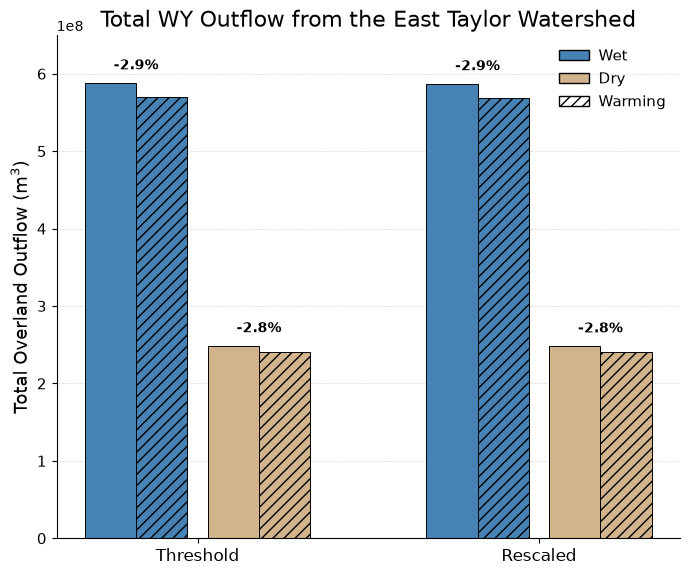

outflow wet baseline threshold :  587575023.5951535
outflow wet baseline rescaled :  586426559.0115478
outflow wet warm threshold :  570534449.8917458
outflow wet warm rescaled :  569227554.218094
outflow dry baseline threshold :  248028728.5142967
outflow dry baseline rescaled :  247743097.82698193
outflow dry warm threshold :  241170981.9185733
outflow dry warm rescaled :  240862193.03208202


In [12]:
wet_threshold_pct = (
    (outflow_wet_w_tot_rz0 - outflow_wet_b_tot_rz0)
    / outflow_wet_b_tot_rz0 * 100
)

wet_rescaled_pct = (
    (outflow_wet_w_tot - outflow_wet_b_tot)
    / outflow_wet_b_tot * 100
)

dry_threshold_pct = (
    (outflow_dry_w_tot_rz0 - outflow_dry_b_tot_rz0)
    / outflow_dry_b_tot_rz0 * 100
)

dry_rescaled_pct = (
    (outflow_dry_w_tot - outflow_dry_b_tot)
    / outflow_dry_b_tot * 100
)

x = np.array([0, 1])

width = 0.15
group_gap = 0.06

wet_color = 'steelblue'
dry_color = 'tan'

wet_baseline_pos = (
    x - 1.5 * width - group_gap / 2
)

wet_warm_pos = (
    x - 0.5 * width - group_gap / 2
)

dry_baseline_pos = (
    x + 0.5 * width + group_gap / 2
)

dry_warm_pos = (
    x + 1.5 * width + group_gap / 2
)


wet_baseline_vals = [
    outflow_wet_b_tot_rz0,
    outflow_wet_b_tot
]

wet_warm_vals = [
    outflow_wet_w_tot_rz0,
    outflow_wet_w_tot
]

dry_baseline_vals = [
    outflow_dry_b_tot_rz0,
    outflow_dry_b_tot
]

dry_warm_vals = [
    outflow_dry_w_tot_rz0,
    outflow_dry_w_tot
]

wet_pcts = [
    wet_threshold_pct,
    wet_rescaled_pct
]

dry_pcts = [
    dry_threshold_pct,
    dry_rescaled_pct
]


fig, ax_bar = plt.subplots(figsize=(7, 6))


# Wet baseline
ax_bar.bar(
    wet_baseline_pos,
    wet_baseline_vals,
    width=width,
    color=wet_color,
    edgecolor='black',
    linewidth=0.7
)

# Wet warming
ax_bar.bar(
    wet_warm_pos,
    wet_warm_vals,
    width=width,
    color=wet_color,
    edgecolor='black',
    linewidth=0.7,
    hatch='///'
)

# Dry baseline
ax_bar.bar(
    dry_baseline_pos,
    dry_baseline_vals,
    width=width,
    color=dry_color,
    edgecolor='black',
    linewidth=0.7
)

# Dry warming
ax_bar.bar(
    dry_warm_pos,
    dry_warm_vals,
    width=width,
    color=dry_color,
    edgecolor='black',
    linewidth=0.7,
    hatch='///'
)

ax_bar.set_xticks(x)

ax_bar.set_xticklabels(
    ['Threshold', 'Rescaled'],
    fontsize=13
)

ax_bar.set_ylabel(
    'Total Overland Outflow (m$^3$)',
    fontsize=13
)

ax_bar.tick_params(
    axis='y',
    labelsize=11
)

ax_bar.tick_params(
    axis='x',
    labelsize=12
)

ax_bar.spines['top'].set_visible(False)
ax_bar.spines['right'].set_visible(False)

all_bar_vals = (
    wet_baseline_vals
    + wet_warm_vals
    + dry_baseline_vals
    + dry_warm_vals
)

bar_max = max(all_bar_vals)
bar_min = min(all_bar_vals)

bar_range = bar_max - bar_min

if bar_range == 0:
    bar_range = 1


for i in range(2):

    wet_center = (
        wet_baseline_pos[i]
        + wet_warm_pos[i]
    ) / 2

    dry_center = (
        dry_baseline_pos[i]
        + dry_warm_pos[i]
    ) / 2


    wet_top = max(
        wet_baseline_vals[i],
        wet_warm_vals[i]
    )

    dry_top = max(
        dry_baseline_vals[i],
        dry_warm_vals[i]
    )


    ax_bar.text(
        wet_center,
        wet_top + 0.04 * bar_range,
        f'{wet_pcts[i]:+.1f}%',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

    ax_bar.text(
        dry_center,
        dry_top + 0.04 * bar_range,
        f'{dry_pcts[i]:+.1f}%',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

ax_bar.grid(
    axis='y',
    linestyle='--',
    linewidth=0.6,
    alpha=0.35
)

ax_bar.set_axisbelow(True)

ax_bar.set_ylim(
    0,
    bar_max + 0.18 * bar_range
)

legend_handles = [
    Patch(
        facecolor=wet_color,
        edgecolor='black',
        label='Wet'
    ),
    Patch(
        facecolor=dry_color,
        edgecolor='black',
        label='Dry'
    ),
    Patch(
        facecolor='white',
        edgecolor='black',
        hatch='///',
        label='Warming'
    )
]

ax_bar.legend(
    handles=legend_handles,
    frameon=False,
    fontsize=11,
    loc='upper right',
    ncol=1,
    columnspacing=1.5,
    handletextpad=0.6
)

plt.title('Total WY Outflow from the East Taylor Watershed', fontsize = 16)

plt.tight_layout()
plt.show()

print('outflow wet baseline threshold : ', outflow_wet_b_tot_rz0)
print('outflow wet baseline rescaled : ', outflow_wet_b_tot)


print('outflow wet warm threshold : ', outflow_wet_w_tot_rz0)
print('outflow wet warm rescaled : ', outflow_wet_w_tot)


print('outflow dry baseline threshold : ', outflow_dry_b_tot_rz0)
print('outflow dry baseline rescaled : ', outflow_dry_b_tot)


print('outflow dry warm threshold : ', outflow_dry_w_tot_rz0)
print('outflow dry warm rescaled : ', outflow_dry_w_tot)
